# E103: Fingerprint MLP + library cosine blend

Run this notebook **after E101 and E102 have finished training and evaluation**, using the same environment and stage. CPU execution is sufficient. It reuses the saved checkpoints, metrics, competition data, and reference. It writes E103 results only; it does not train models or rebuild the reference.

Do not run it concurrently with notebook 02: notebook 02 still contains its original E103 cells and was intentionally left unchanged. No package installation or runtime restart is performed here.


In [1]:
from pathlib import Path
import os

DRIVE_MOUNT = Path(os.environ.get('CASMI_DRIVE_MOUNT', '/content/drive'))
PROJECT = Path(os.environ.get('CASMI_PROJECT', str(DRIVE_MOUNT / 'MyDrive/Data266/EnvedaGroupProject')))
REPO = PROJECT / 'repo'
TRAIN = REPO / 'data/raw/train.parquet'
OUTPUT = Path(os.environ.get('CASMI_OUTPUT', str(PROJECT / 'cyril')))
STAGE = os.environ.get('CASMI_STAGE', 'final')
assert STAGE in ('smoke', 'debug', 'final')
RUNS = OUTPUT / STAGE
REF = OUTPUT / 'reference'
print('E103 stage:', STAGE)
print('Saved E101/E102 runs:', RUNS)
print('E103 outputs:', RUNS / 'E103')

E103 stage: final
Saved E101/E102 runs: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final
E103 outputs: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final/E103


In [2]:
import hashlib
import json
import sys

# Reuse an existing mount. A fresh Colab runtime may request Drive authorization.
if not (REPO / 'members/mrcyrilgoud/model_mlp.py').is_file():
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT))
assert (REPO / 'members/mrcyrilgoud/model_mlp.py').is_file(), 'Project source is missing from REPO.'
assert TRAIN.is_file(), 'Use the existing competition parquet from the training runs.'

current_source = {
    str(p.relative_to(REPO)): hashlib.sha256(p.read_bytes()).hexdigest()
    for folder in ('src', 'members/mrcyrilgoud')
    for p in (REPO / folder).rglob('*.py')
}
if '_CYRIL_SOURCE_SNAPSHOT' in globals() and current_source != _CYRIL_SOURCE_SNAPSHOT:
    raise RuntimeError('Loaded source differs from the saved runtime snapshot. Use the original training source.')

# The shared evaluator expects repo/data/raw/train.parquet relative to this directory.
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from members.mrcyrilgoud.model_mlp import evaluate_blends, validated_evaluations
from members.mrcyrilgoud.baseline_audit import audit_baseline, require_same_baseline
print('Existing dependencies loaded. E103 scoring runs on CPU.')

Existing dependencies loaded. E103 scoring runs on CPU.


In [3]:
# Read completed artifacts; never start/resume training or regenerate E101/E102 metrics.
required = [RUNS / 'baseline/metrics.json', RUNS / 'baseline_audit/audit.json',
            REF / 'source.json', REF / 'ref_meta.parquet', REF / 'ref_peaks.npz',
            REF / 'structures.parquet']
for experiment in ('E101', 'E102'):
    required.extend(RUNS / experiment / name for name in
                    ('best.pt', 'training.json', 'evaluation/metrics.json'))
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError('Finish both training/evaluation notebooks first. Missing: ' + ', '.join(missing))

standalone, baseline = validated_evaluations(RUNS, REF)
saved_audit = json.loads((RUNS / 'baseline_audit/audit.json').read_text())
assert abs(baseline['mrr'] - saved_audit['shared']['mrr']) < 1e-12, 'Saved baseline and audit disagree.'
print('Saved baseline MRR@25:', baseline['mrr'])
for experiment, metrics in standalone.items():
    print(experiment, 'MRR@25:', metrics['mrr'])

Saved baseline MRR@25: 0.8913602175602175
E101 MRR@25: 0.41883574863389106
E102 MRR@25: 0.47101694812075345


In [4]:
# Write the fresh audit under E103; preserve the original baseline and model metrics.
current_audit = audit_baseline(TRAIN, REF, RUNS / 'E103/baseline_audit')
require_same_baseline(saved_audit, current_audit)
print('Baseline context matches the saved E101/E102 evaluations.')

Baseline audit: loading validation and reference...
Baseline audit: verifying data and reference identities...
Shared cosine MRR@25: 0.891360; original ranking: 0.891360; changed molecules: 0
Ranking policy comparison measured; the remaining historical difference is not established without the original environment/reference.
Baseline context matches the saved E101/E102 evaluations.


[fp-mlp-loss_metadata-blend-0.1] MRR@25 = 0.8935 | top-1 0.840 | top-10 0.980 | top-25 0.992 | 250 molecules | 4s
[fp-mlp-loss_metadata-blend-0.2] MRR@25 = 0.8955 | top-1 0.844 | top-10 0.980 | top-25 0.996 | 250 molecules | 1s
[fp-mlp-loss_metadata-blend-0.3] MRR@25 = 0.8931 | top-1 0.836 | top-10 0.984 | top-25 0.996 | 250 molecules | 1s
[fp-mlp-loss_metadata-blend-0.5] MRR@25 = 0.8890 | top-1 0.828 | top-10 0.984 | top-25 0.996 | 250 molecules | 1s


,alpha,mrr
0,0.0,0.891360
2,0.1,0.893519
3,0.2,0.895501
4,0.3,0.893105
5,0.5,0.888956
1,1.0,0.471017


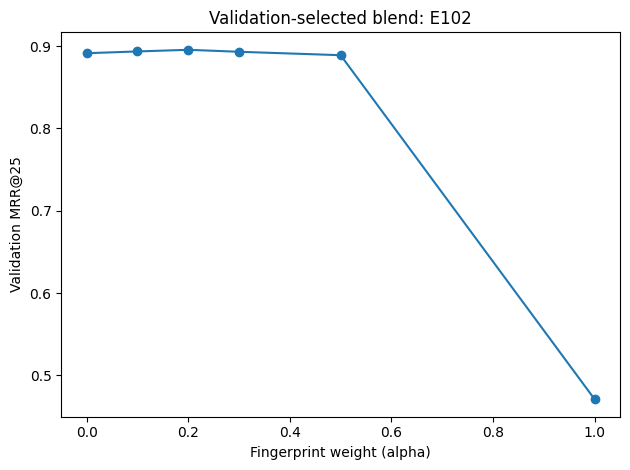

In [5]:
# Select the better standalone model, then test the four requested blend weights.
# The returned curve also contains alpha=0 (baseline) and alpha=1 (standalone).
curve = evaluate_blends(RUNS, REF)
display(curve)

In [6]:
selection = json.loads((RUNS / 'E103/selection.json').read_text())
print('Selected model:', selection['model'])
print('Best tested blend alpha:', selection['alpha'])
print('Blend MRR@25:', selection['mrr'])
print('Change versus measured baseline:', selection['mrr'] - baseline['mrr'])
print('Selection uses the shared validation set; it is not an independent test score.')
print('Saved curve:', RUNS / 'E103/blend_curve.csv')
print('Saved figure:', RUNS / 'E103/blend_curve.png')
print('Saved selection:', RUNS / 'E103/selection.json')

Selected model: E102
Best tested blend alpha: 0.2
Blend MRR@25: 0.89550101010101
Change versus measured baseline: 0.004140792540792471
Selection uses the shared validation set; it is not an independent test score.
Saved curve: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final/E103/blend_curve.csv
Saved figure: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final/E103/blend_curve.png
Saved selection: /content/drive/MyDrive/Data266/EnvedaGroupProject/cyril/final/E103/selection.json
